# Lab 04 — Data Drift x Concept Drift: o alerta prova degradação?

**RMC AI Labs | MLOps Mini**

Continuação direta do Lab 03 (`posts/data_drift`): antes medimos PSI sem rótulos; agora comparamos PSI e MAE quando os valores observados se tornam disponíveis. **Todas as amostras e alvos deste Lab 04 são sintéticos**, não representam servidores reais. Não há conexão cloud nem alterações no Lab 03.

## 1. Desenho experimental

- **Controle**: distribuição de CPU próxima da referência e mesma relação entrada–alvo.
- **Data Drift**: distribuição de CPU deslocada, mas relação entrada–alvo preservada.
- **Concept Drift**: mesmas entradas do Data Drift, mas valores observados deslocados em +12 pontos.

O preditor é `memória = 15 + 0.7 × CPU`. O objetivo é mostrar que **o PSI pode ser alto sem MAE alto**, e que alteração da relação entrada–alvo pode aumentar o erro. O PSI não distingue sozinho os dois últimos cenários.

In [1]:
from pathlib import Path
print('Diretório do laboratório:', Path.cwd())
%run executar_lab04.py

Diretório do laboratório: /home/francisco/PythonProjects/LAB_POSTS/mlops/rmc-mlops-mini/posts/model_drift
{
  "controle": {
    "psi": 0.06273249501318233,
    "mae": 1.5945938292458464,
    "alerta_entrada": false,
    "alerta_desempenho": false
  },
  "data_drift": {
    "psi": 9.299165100258678,
    "mae": 1.6142406313197017,
    "alerta_entrada": true,
    "alerta_desempenho": false
  },
  "concept_drift": {
    "psi": 9.299165100258678,
    "mae": 11.945942296441304,
    "alerta_entrada": true,
    "alerta_desempenho": true
  }
}
Evidências criadas em figuras/


## 2. O que os resultados demonstram

Compare `figuras/distribuicoes.png`, `figuras/psi_mae_comparacao.png` e `figuras/resultados.json`. O cenário de Data Drift preserva o mapeamento entre CPU e memória e deve manter MAE baixo apesar do PSI elevado. O cenário de Concept Drift utiliza exatamente os mesmos valores de CPU, porém muda os valores observados, fazendo o MAE aumentar.

**Limitações:** MAE exige rótulos confiáveis e disponíveis; PSI depende de amostragem, bandas e tamanho da janela. Os limites 0,25 e MAE 5 são apenas regras de demonstração, não critérios universais. Em produção, investigar qualidade da coleta, sazonalidade, mudança de população e impacto de negócio antes de retreinar.

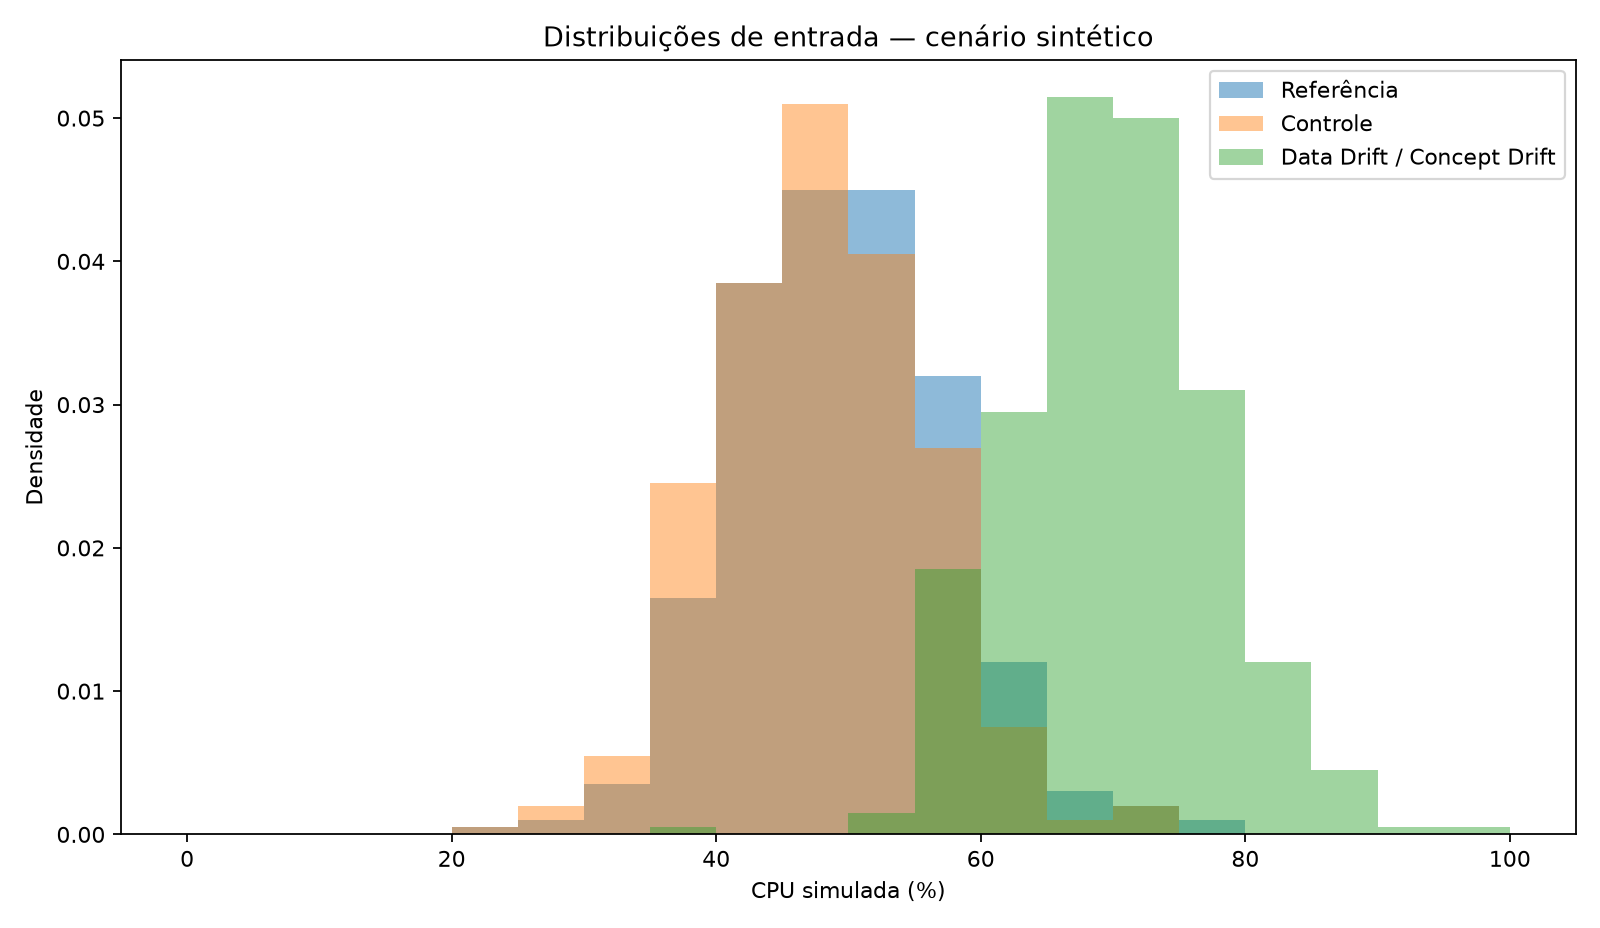

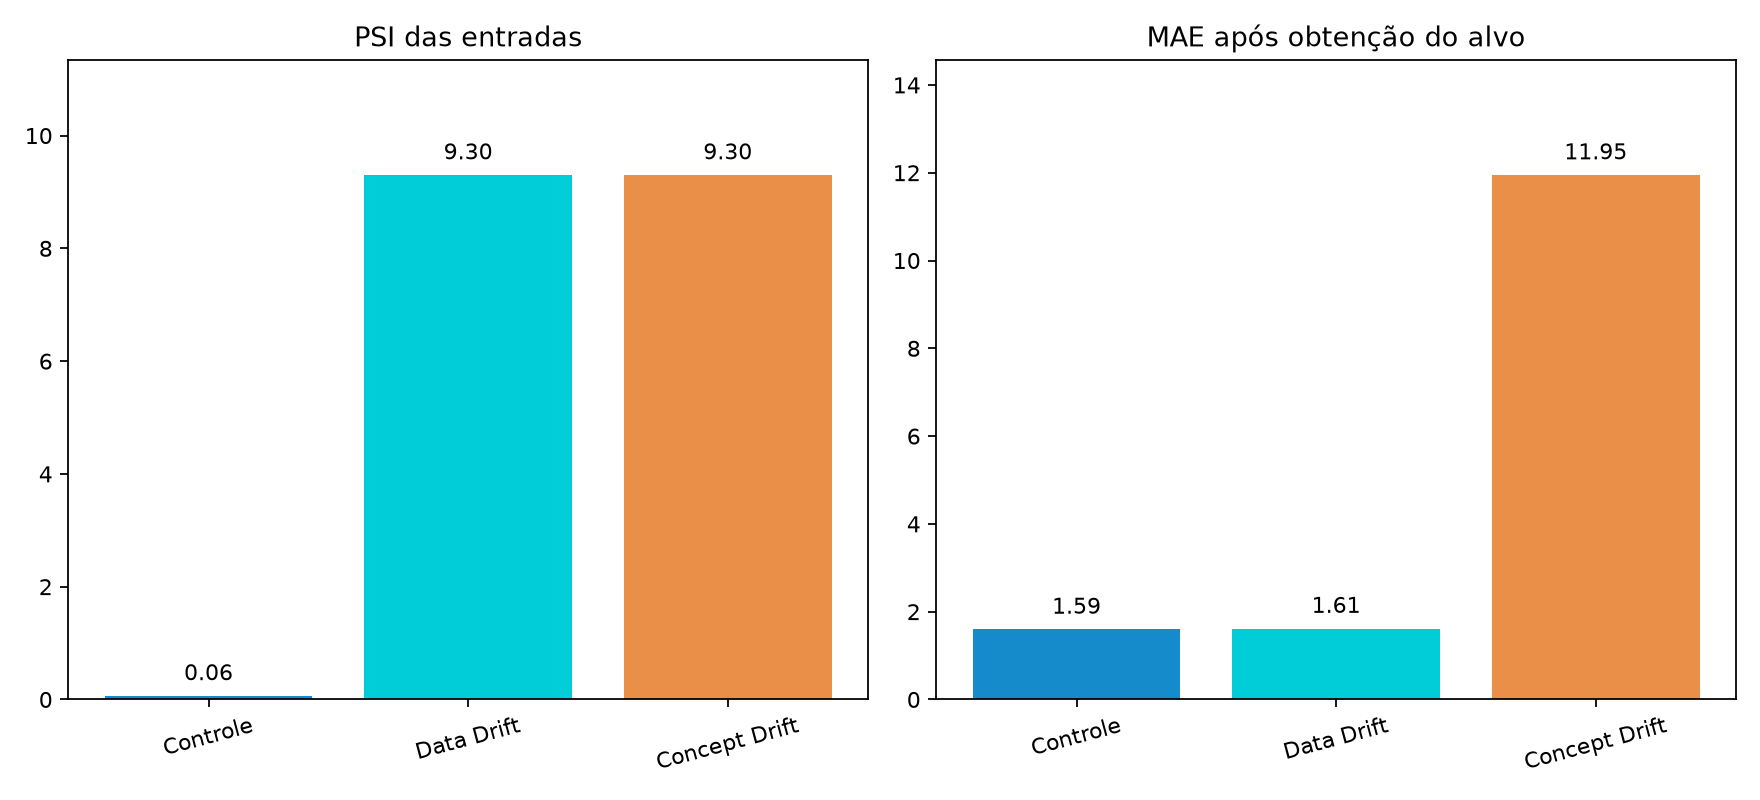

In [2]:
from IPython.display import display, Image
display(Image(filename='figuras/distribuicoes.png'))
display(Image(filename='figuras/psi_mae_comparacao.png'))

## 3. Continuidade

O Lab 05 poderá incorporar janelas temporais, métricas por VM/cluster e política de monitoramento auditável, usando dados autorizados e pseudonimizados do laboratório de infraestrutura. Não realizar retreinamento automático só porque o PSI ultrapassou um valor de referência.